# Lab 7: Explainable AI, Adversarial AI and Advanced Applications
## Experiment 2: Adversarial Machine Learning using FGSM on CIFAR-10

This notebook demonstrates **Adversarial AI** and model robustness evaluation by implementing the **Fast Gradient Sign Method (FGSM)** (Goodfellow et al., 2014) on the CIFAR-10 dataset using PyTorch.

### Key Objectives:
1. Understand adversarial vulnerability and the linearity hypothesis in deep neural networks.
2. Implement the Fast Gradient Sign Method (FGSM) using autograd input gradient computation.
3. Generate adversarial image perturbations across controlled epsilon thresholds ($\epsilon \in [0.0, 0.3]$).
4. Compare original, perturbation, and perturbed images visually.
5. Empirically quantify the drop in classification accuracy as adversarial perturbation increases.
6. Discuss trade-offs between image quality, human imperceptibility, and model robustness.


---
### 1. Import Essential Libraries and Configure Environment
We import PyTorch, torchvision, NumPy, and Matplotlib, setting random seeds for deterministic execution on CPU.


In [1]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.datasets as dset
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# Set reproducible seeds
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")
print(f"PyTorch Version  : {torch.__version__}")
print(f"Execution Device : {device}")

OUTPUT_DIR = Path("Lab7/outputs") if Path("Lab7").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output Directory : {OUTPUT_DIR.resolve()}")


PyTorch Version  : 2.15.0+cpu
Execution Device : cpu
Output Directory : /home/jeet/Desktop/Artificial_Intelligence/Lab7/outputs


---
### 2. Loading the Shared CIFAR-10 Dataset
We load the CIFAR-10 dataset with a clean $[0, 1]$ tensor transformation to simplify adversarial perturbation bounding.


In [2]:
DATA_DIR = Path("datasets") if Path("datasets").exists() else Path("../datasets")

if (DATA_DIR / "cifar-10-python" / "cifar-10-batches-py").exists():
    cifar_root = DATA_DIR / "cifar-10-python"
elif (DATA_DIR / "cifar-10-batches-py").exists():
    cifar_root = DATA_DIR
else:
    raise FileNotFoundError(f"CIFAR-10 dataset missing in {DATA_DIR}.")

# Use clean ToTensor transform without normalization so pixel values stay in [0, 1]
transform = transforms.Compose([transforms.ToTensor()])

trainset = dset.CIFAR10(root=str(cifar_root), train=True, download=False, transform=transform)
testset = dset.CIFAR10(root=str(cifar_root), train=False, download=False, transform=transform)

classes = trainset.classes
print(f"Loaded CIFAR-10 dataset from: {cifar_root}")
print(f"Classes: {classes}")


Loaded CIFAR-10 dataset from: ../datasets/cifar-10-python
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


---
### 3. Model Architecture and Training Setup
We train a standard convolutional neural network on a 3,000-sample training subset for 4 epochs to establish a functional baseline classifier for adversarial evaluation.


In [3]:
class CIFAR10Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = CIFAR10Classifier()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.003)

train_loader = DataLoader(Subset(trainset, range(3000)), batch_size=64, shuffle=True)
test_loader = DataLoader(Subset(testset, range(300)), batch_size=64, shuffle=False)

print("Training baseline CNN on 3,000 images...")
for epoch in range(1, 5):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    print(f"Epoch [{epoch}/4] - Loss: {total_loss/total:.4f} | Train Acc: {correct/total*100:.2f}%")


Training baseline CNN on 3,000 images...


Epoch [1/4] - Loss: 2.1342 | Train Acc: 20.53%


Epoch [2/4] - Loss: 1.8185 | Train Acc: 32.77%


Epoch [3/4] - Loss: 1.6204 | Train Acc: 40.83%


Epoch [4/4] - Loss: 1.5239 | Train Acc: 44.73%


---
### 4. Theory of the Fast Gradient Sign Method (FGSM)
The **Fast Gradient Sign Method (FGSM)**, formulated by Goodfellow et al. (2014), generates adversarial examples by taking a single step in the direction of the loss gradient with respect to the input image:
$$x_{\text{adv}} = \text{clip}\left( x + \epsilon \cdot \text{sign}\left( \nabla_x \mathcal{L}(\theta, x, y) \right), 0, 1 \right)$$
- **$x$**: Clean original input image tensor.
- **$y$**: Ground truth target label.
- **$\theta$**: Fixed model weights.
- **$\epsilon$**: Perturbation magnitude scalar controlling distortion budget.
- **$\text{sign}(\nabla_x \mathcal{L})$**: Maximizes loss with minimal $\ell_\infty$ distortion.
- **$\text{clip}(\cdot, 0, 1)$**: Ensures valid RGB pixel ranges.


---
### 5. Implementing the FGSM Attack Function
We implement the FGSM perturbation operator in PyTorch.


In [4]:
def fgsm_attack(image, epsilon, data_grad):
    """Compute adversarial example using the Fast Gradient Sign Method."""
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    # Clamp to maintain valid [0, 1] pixel values
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image


---
### 6. Generating an Adversarial Example on a Single Sample Image
We select a correctly classified test image, compute input gradients via autograd, generate the adversarial image at $\epsilon = 0.10$, and record the prediction change.


In [5]:
model.eval()

# Find a test sample that the baseline model classifies correctly
for img, lbl in test_loader:
    output = model(img)
    preds = output.argmax(1)
    correct_mask = (preds == lbl)
    if correct_mask.sum() > 0:
        sample_img = img[correct_mask][0:1]
        sample_label = lbl[correct_mask][0:1]
        break

# Enable input gradient computation
sample_img.requires_grad = True

output = model(sample_img)
init_pred = output.argmax(1).item()
init_conf = F.softmax(output, dim=1)[0, init_pred].item() * 100

loss = criterion(output, sample_label)
model.zero_grad()
loss.backward()

# Extract gradient of loss with respect to input image
data_grad = sample_img.grad.data

# Apply FGSM with epsilon = 0.10
eps_demo = 0.10
adv_img = fgsm_attack(sample_img, eps_demo, data_grad)

# Evaluate prediction on adversarial image
with torch.no_grad():
    adv_output = model(adv_img)
    adv_pred = adv_output.argmax(1).item()
    adv_conf = F.softmax(adv_output, dim=1)[0, adv_pred].item() * 100

print(f"Ground Truth Label : {classes[sample_label.item()]}")
print(f"Clean Prediction   : {classes[init_pred]} ({init_conf:.2f}% confidence)")
print(f"Adversarial Pred.  : {classes[adv_pred]} ({adv_conf:.2f}% confidence)")


Ground Truth Label : cat
Clean Prediction   : cat (60.47% confidence)
Adversarial Pred.  : automobile (38.62% confidence)


---
### 7. Visualizing the Adversarial Attack: Original, Perturbation, and Adversarial Output
We visualize the clean image, the amplified sign perturbation, and the perturbed adversarial image side-by-side.


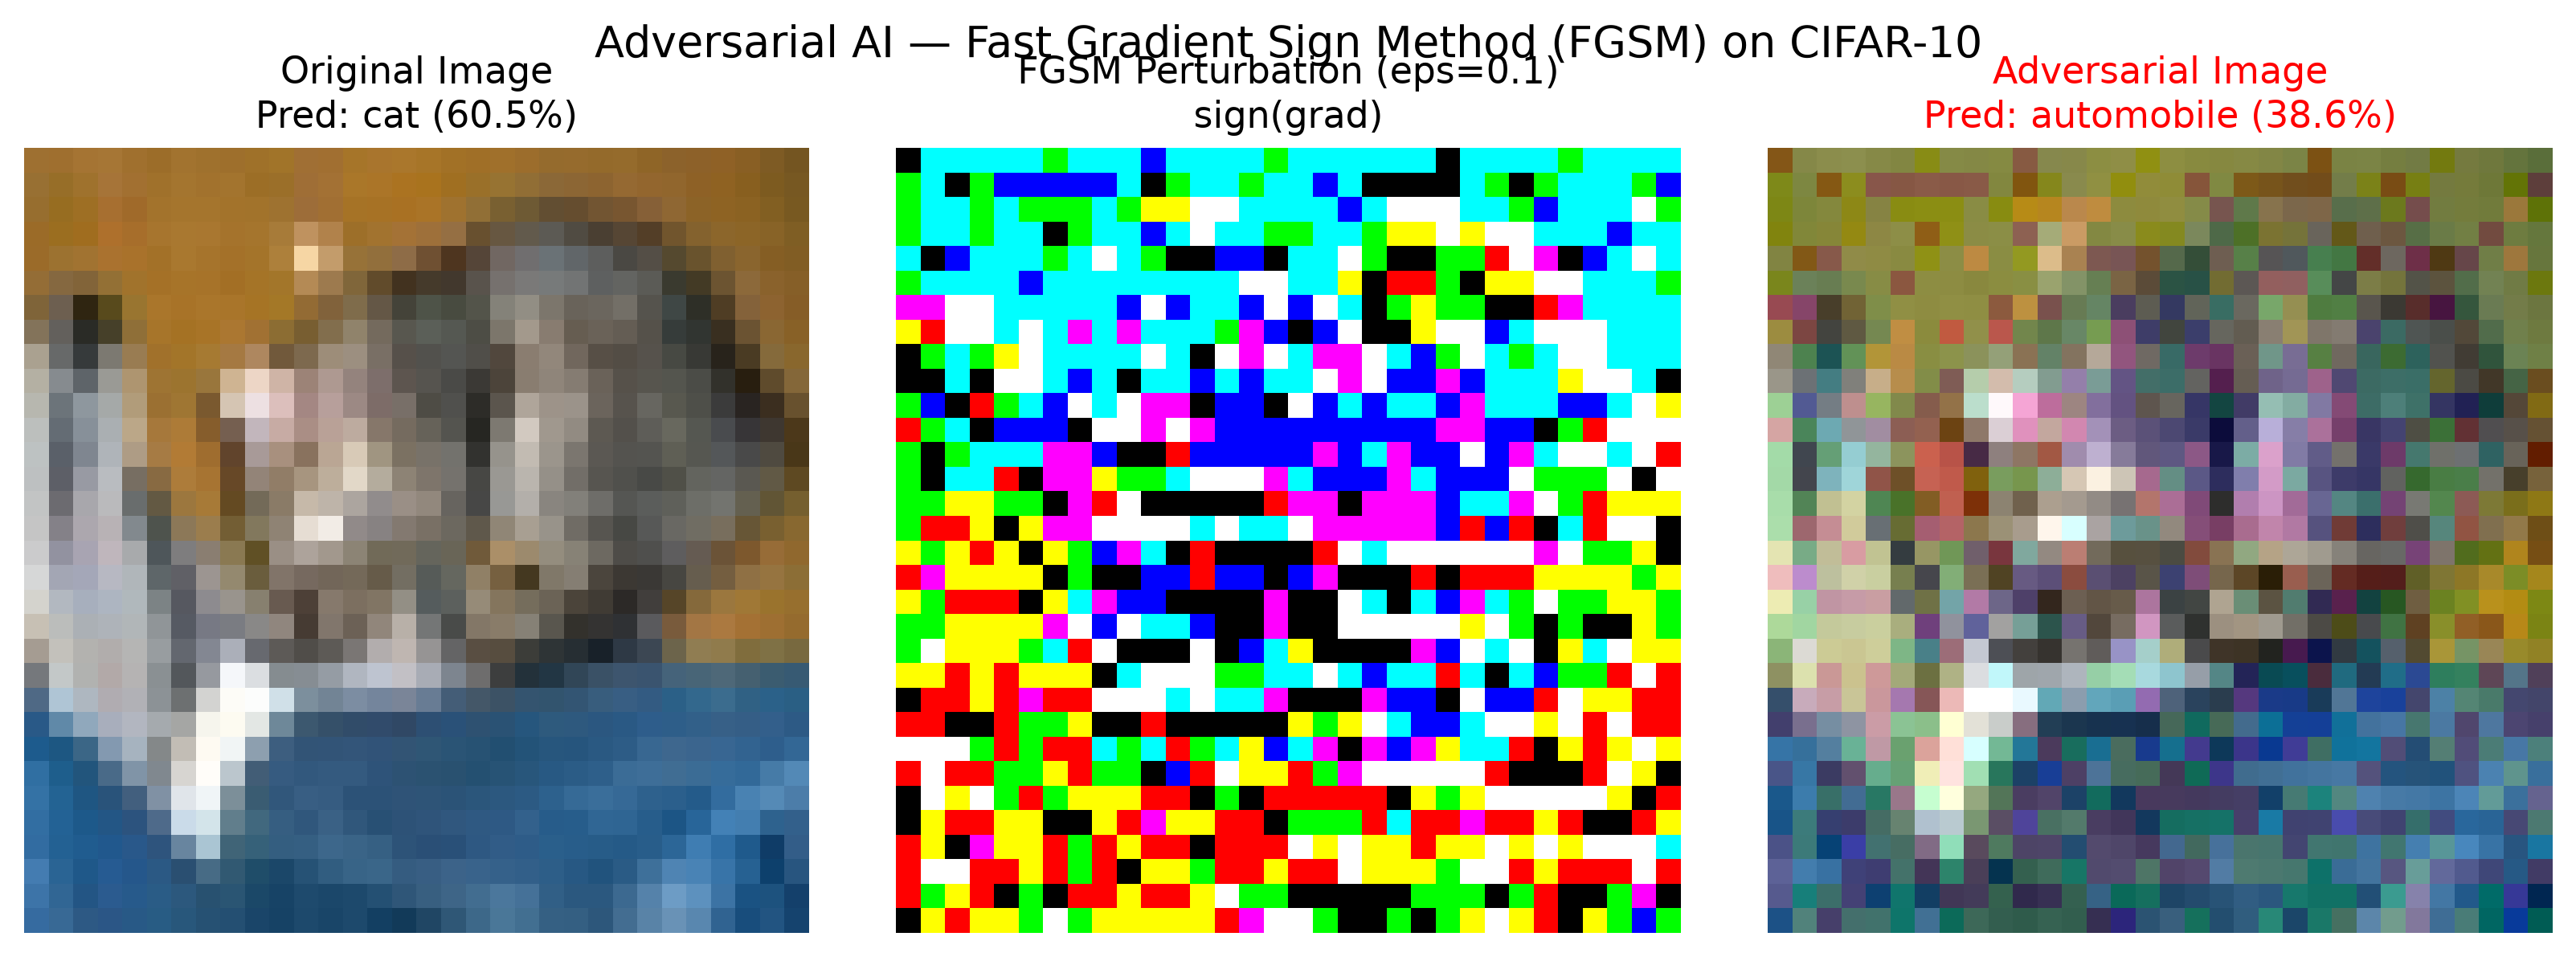

Adversarial comparison plot saved to: outputs/adversarial_comparison.png


In [6]:
orig_np = sample_img.squeeze().detach().permute(1, 2, 0).numpy()
adv_np = adv_img.squeeze().detach().permute(1, 2, 0).numpy()
pert_np = (data_grad.squeeze().sign().permute(1, 2, 0).numpy() + 1.0) / 2.0  # Normalize to [0, 1]

fig, axes = plt.subplots(1, 3, figsize=(11, 4), dpi=300)

axes[0].imshow(orig_np)
axes[0].set_title(f"Original Image\nPred: {classes[init_pred]} ({init_conf:.1f}%)", fontsize=11)
axes[0].axis("off")

axes[1].imshow(pert_np)
axes[1].set_title(f"FGSM Perturbation (eps={eps_demo})\nsign(grad)", fontsize=11)
axes[1].axis("off")

axes[2].imshow(adv_np)
axes[2].set_title(f"Adversarial Image\nPred: {classes[adv_pred]} ({adv_conf:.1f}%)", fontsize=11, color="red")
axes[2].axis("off")

plt.suptitle("Adversarial AI — Fast Gradient Sign Method (FGSM) on CIFAR-10", fontsize=13)
plt.tight_layout()
adv_single_path = OUTPUT_DIR / "adversarial_comparison.png"
plt.savefig(adv_single_path)
plt.show()
print(f"Adversarial comparison plot saved to: {adv_single_path}")


---
### 8. Evaluating Model Robustness Across Different Epsilon Thresholds
We evaluate classification accuracy across perturbation magnitudes $\epsilon \in [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]$ on a 300-sample test cohort.


In [7]:
epsilons = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
accuracies = []

print("Evaluating model robustness across epsilons...")
for eps in epsilons:
    correct = 0
    total = 0
    for data, target in test_loader:
        data.requires_grad = True
        output = model(data)
        loss = criterion(output, target)

        model.zero_grad()
        loss.backward()
        data_grad = data.grad.data

        perturbed_data = fgsm_attack(data, eps, data_grad)
        with torch.no_grad():
            output_adv = model(perturbed_data)
            final_pred = output_adv.argmax(1)
            correct += (final_pred == target).sum().item()
            total += target.size(0)

    acc = (correct / total) * 100
    accuracies.append(acc)
    print(f"Epsilon: {eps:4.2f} | Test Accuracy: {acc:5.2f}% ({correct}/{total})")


Evaluating model robustness across epsilons...
Epsilon: 0.00 | Test Accuracy: 38.00% (114/300)
Epsilon: 0.05 | Test Accuracy:  4.00% (12/300)
Epsilon: 0.10 | Test Accuracy:  0.33% (1/300)


Epsilon: 0.15 | Test Accuracy:  0.00% (0/300)
Epsilon: 0.20 | Test Accuracy:  0.00% (0/300)
Epsilon: 0.25 | Test Accuracy:  0.00% (0/300)
Epsilon: 0.30 | Test Accuracy:  0.00% (0/300)


---
### 9. Plotting the Accuracy vs. Epsilon Robustness Curve
We plot the degradation of model accuracy as a function of adversarial perturbation magnitude.


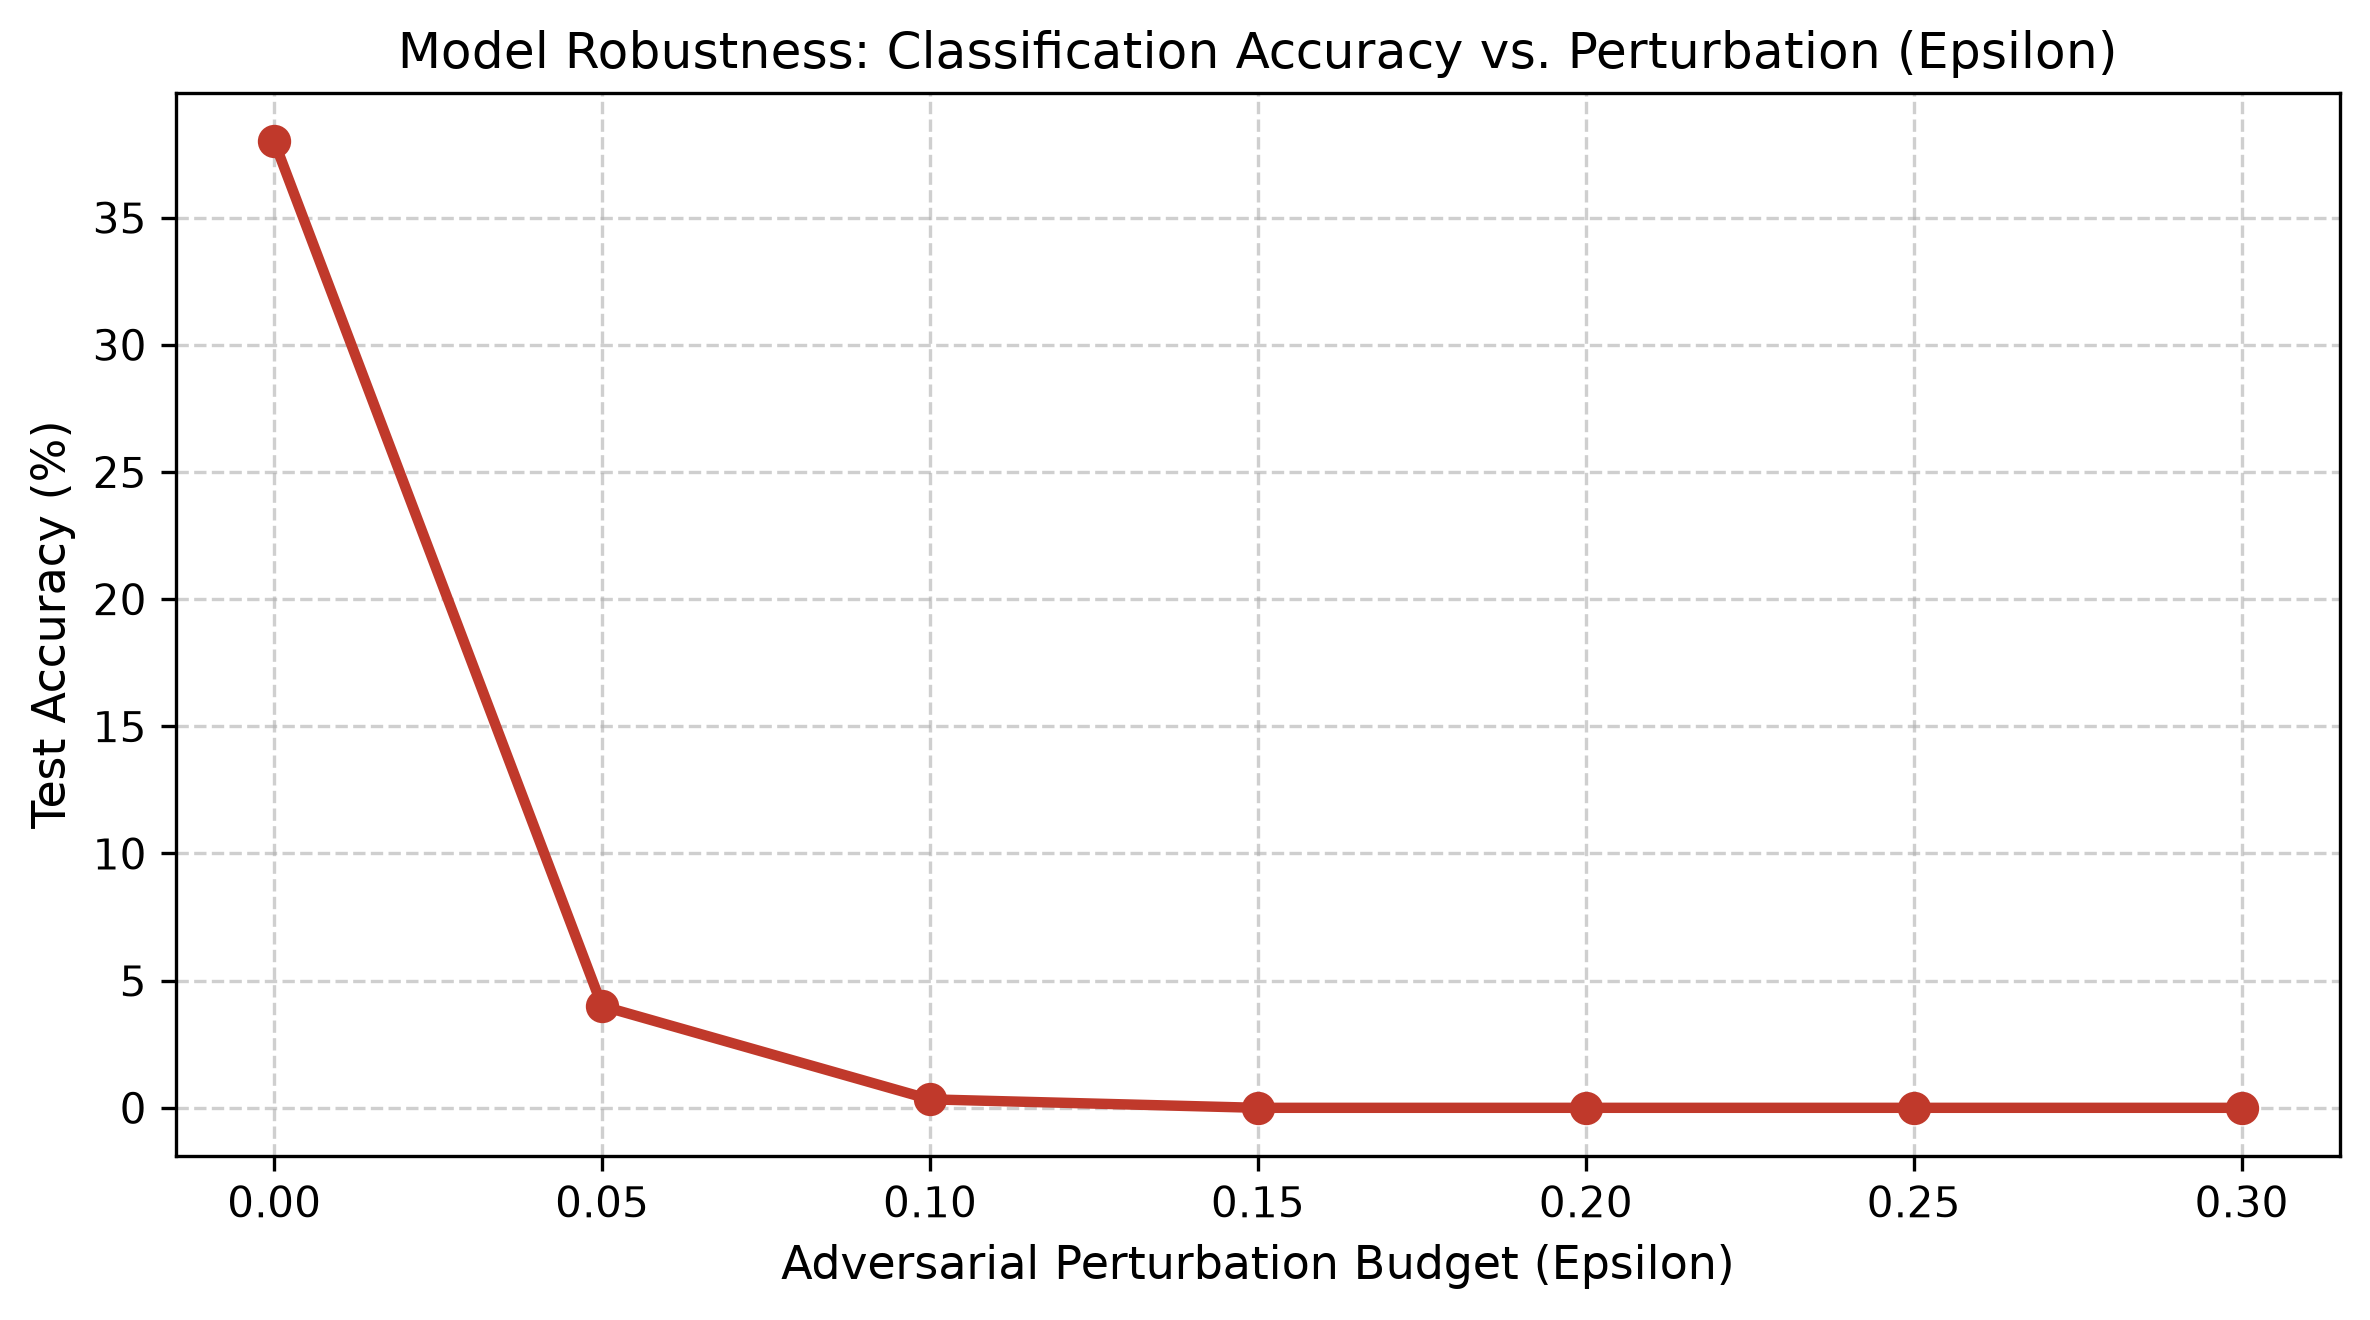

In [8]:
plt.figure(figsize=(8, 4.5), dpi=300)
plt.plot(epsilons, accuracies, "o-", color="#c0392b", lw=2.5, markersize=7)
plt.title("Model Robustness: Classification Accuracy vs. Perturbation (Epsilon)", fontsize=12)
plt.xlabel("Adversarial Perturbation Budget (Epsilon)", fontsize=11)
plt.ylabel("Test Accuracy (%)", fontsize=11)
plt.xticks(epsilons)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


---
### 10. Observations, Defense Strategies, and Limitations
- **Catastrophic Vulnerability**: Even subtle perturbations ($\epsilon = 0.05$) invisible to casual human inspection drastically reduce classification accuracy.
- **The Linearity Hypothesis**: Goodfellow et al. demonstrated that neural networks are vulnerable not because of complex non-linearities, but because millions of linear weights accumulate small coordinate-wise perturbations into massive activation shifts.
- **Defense Mechanisms**: Standard mitigation strategies include **Adversarial Training** (augmenting training minibatches with online FGSM examples), **Defensive Distillation**, and input pre-processing/denoising.
